# 007 Medium — Moments

`P_max, cN2_max, L_inj, dip_frac, x_of + plane_mm → mean_zeta_um, mean_y_um, mean_z_um, mean_ux, mean_uy, mean_uz, sigma_zeta, sigma_y, sigma_z, sigma_ux, sigma_uy, sigma_uz, q_tot_pC`

In [42]:
import pandas as pd

PACK = "/Users/netanmangal/Documents/netanmangal/ganil-artifact-hackathon-2026/challenges/surrogate-models/full-data"
data = pd.read_parquet(f"{PACK}/campaign_B_moments.parquet")
data = data[data.group == 'all']

# data.groupby(data.n_stored).count()
# data.head()

data.columns.to_numpy()

# data.n_stored.min(), data.n_stored.max(), 

# data.groupby(data.group).count()

array(['n_stored', 'n_raw', 'n_used', 'present_frac', 'q_tot_pC',
       'q_raw_pC', 'injection', 'xa0_mm', 'ts_lo', 'ts_hi', 'frac',
       'interp', 'ref_plane_mm', 'w_sum', 'ess', 'charge_closure',
       'mean_zeta_um', 'mean_y_um', 'mean_z_um', 'mean_ux', 'mean_uy',
       'mean_uz', 'cov_00', 'cov_01', 'cov_02', 'cov_03', 'cov_04',
       'cov_05', 'cov_11', 'cov_12', 'cov_13', 'cov_14', 'cov_15',
       'cov_22', 'cov_23', 'cov_24', 'cov_25', 'cov_33', 'cov_34',
       'cov_35', 'cov_44', 'cov_45', 'cov_55', 'E_mean_MeV', 'E_med_MeV',
       'E_p16_MeV', 'E_p84_MeV', 'E_std_MeV', 'E_mad_MeV', 'sim_id',
       'plane_mm', 'group', 'x_of', 'P_max', 'cN2_max', 'L_inj',
       'dip_frac'], dtype=object)

## Setup

In [46]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from pallas_score import normalised_to_physical, physical_to_normalised, score_submission

PACK = "/Users/netanmangal/Documents/netanmangal/ganil-artifact-hackathon-2026/challenges/surrogate-models/full-data"

TARGETS = ["mean_zeta_um", "mean_y_um", "mean_z_um", "mean_ux", "mean_uy", "mean_uz"]# "sigma_zeta", "sigma_y", "sigma_z", "sigma_ux", "sigma_uy", "sigma_uz", 'q_tot_pC']
FEATURES = ["P_max", "cN2_max", "L_inj", "dip_frac", "x_of", "plane_mm"]
KEY = ["row_id"]

data = pd.read_parquet(f"{PACK}/campaign_B_moments.parquet")
data = data[(data.group == "all") & (data.q_tot_pC > 0)]
data["row_id"] = np.arange(len(data))
test_inputs = pd.read_parquet(f"{PACK}/test_moments_planes.parquet")
ids = data.row_id.to_numpy()


def features(frame):
    return frame[FEATURES].to_numpy()


def targets(frame):
    return np.column_stack([physical_to_normalised(t, frame[t]) for t in TARGETS])


def physical(pred):
    return np.column_stack([normalised_to_physical(t, pred[:, i]) for i, t in enumerate(TARGETS)])


def score(pred, frame, zone=None):
    pred = pd.DataFrame(physical(pred), columns=TARGETS)
    pred.insert(0, "row_id", frame.row_id.to_numpy())
    return score_submission(pred, frame[KEY + TARGETS], zone=zone)


def rows_of(rows):
    return data[data.row_id.isin(rows)]


train_id, test_id = train_test_split(ids, test_size=0.2, random_state=0)
train, test = rows_of(train_id), rows_of(test_id)
print(f"{len(data):,} rows with a bunch, {len(train):,} train / {len(test):,} test")

103,083 rows with a bunch, 82,466 train / 20,617 test


## Linear baseline

In [47]:
lin = make_pipeline(StandardScaler(), LinearRegression()).fit(features(train), targets(train))
score(lin.predict(features(test)), test)

{'mean_zeta_um': 0.2637461759165308,
 'mean_y_um': 0.0005513116210967839,
 'mean_z_um': 0.0003969703241547551,
 'mean_ux': 0.4172554754581499,
 'mean_uy': -5.312764787901436e-05,
 'mean_uz': 4.707210359433667e-05,
 'mean': 0.11365731296260793,
 'n_rows': 20617}

## Random forest

In [48]:
rf = RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=0).fit(features(train), targets(train))
score(rf.predict(features(test)), test)

{'mean_zeta_um': 0.7750734743375615,
 'mean_y_um': 0.6554338007385234,
 'mean_z_um': 0.6122365324575995,
 'mean_ux': 0.9945344611196497,
 'mean_uy': 0.31041893094779727,
 'mean_uz': 0.28232983717091154,
 'mean': 0.6050045061286738,
 'n_rows': 20617}

## MLP

In [ ]:
def fit_mlp(train, val, epochs=30, batch=512):
    scaler = StandardScaler().fit(features(train))
    y_mean, y_std = targets(train).mean(0), targets(train).std(0)
    to_X = lambda f: torch.tensor(scaler.transform(features(f)), dtype=torch.float32)
    to_y = lambda f: torch.tensor((targets(f) - y_mean) / y_std, dtype=torch.float32)
    X, y, Xv, yv = to_X(train), to_y(train), to_X(val), to_y(val)

    net = nn.Sequential(nn.Linear(X.shape[1], 64), nn.ReLU(), 
                        nn.Linear(64, 256), nn.ReLU(), 
                        nn.Linear(256, 1024), nn.ReLU(), 
                        nn.Linear(1024, 4096), nn.ReLU(),
                        nn.Linear(4096, 4096), nn.ReLU(),
                        nn.Linear(4096, 4096), nn.ReLU(),
                        nn.Linear(4096, 4096), nn.ReLU(),
                        nn.Linear(4096, 4096), nn.ReLU(),
                        nn.Linear(4096, 1024), nn.ReLU(), 
                        nn.Linear(1024, 256), nn.ReLU(), 
                        nn.Linear(256, 64), nn.ReLU(), 
                        nn.Linear(64, len(TARGETS)))
    opt = torch.optim.Adam(net.parameters(), lr=1e-3)
    loss_fn = nn.MSELoss()

    val_loss = []
    for epoch in range(epochs):
        perm = torch.randperm(len(X))
        for i in range(0, len(X), batch):
            idx = perm[i:i + batch]
            opt.zero_grad()
            loss_fn(net(X[idx]), y[idx]).backward()
            opt.step()
        with torch.no_grad():
            val_loss.append(loss_fn(net(Xv), yv).item())

    def predict(frame):
        with torch.no_grad():
            return net(to_X(frame)).numpy() * y_std + y_mean

    return predict, val_loss


torch.manual_seed(0)
mlp, val_loss = fit_mlp(train, test)
print("val loss", [round(v, 4) for v in val_loss[4::5]])
score(mlp(test), test)

## Cross validation

In [52]:
rows, curves = [], []
for k, (tr, va) in enumerate(KFold(5, shuffle=True, random_state=0).split(ids)):
    tr, va = rows_of(ids[tr]), rows_of(ids[va])
    lin_k = make_pipeline(StandardScaler(), LinearRegression()).fit(features(tr), targets(tr))
    rf_k = RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=0).fit(features(tr), targets(tr))
    torch.manual_seed(k)
    mlp_k, val_loss = fit_mlp(tr, va)
    curves.append(val_loss)
    rows.append({"linear": score(lin_k.predict(features(va)), va)["mean"],
                 "rf": score(rf_k.predict(features(va)), va)["mean"],
                 "mlp": score(mlp_k(va), va)["mean"]})
    print(f"fold {k}  mlp val loss {val_loss[-1]:.4f}  min {min(val_loss):.4f} at epoch {np.argmin(val_loss) + 1}")

cv = pd.DataFrame(rows)
cv.loc["mean"] = cv.mean()
cv.loc["std"] = cv.iloc[:-1].std()
cv.round(4)

fold 0  mlp val loss 0.4070  min 0.4070 at epoch 30
fold 1  mlp val loss 0.4480  min 0.4480 at epoch 30
fold 2  mlp val loss 0.4711  min 0.4470 at epoch 29
fold 3  mlp val loss 0.4240  min 0.4240 at epoch 30
fold 4  mlp val loss 0.4315  min 0.4052 at epoch 28


,linear,rf,mlp
0,0.1137,0.6050,0.5960
1,0.1141,0.5405,0.5870
2,0.1170,0.6038,0.5479
3,0.1145,0.5745,0.5795
4,0.1131,0.5657,0.4952
mean,0.1145,0.5779,0.5611
std,0.0015,0.0272,0.0411


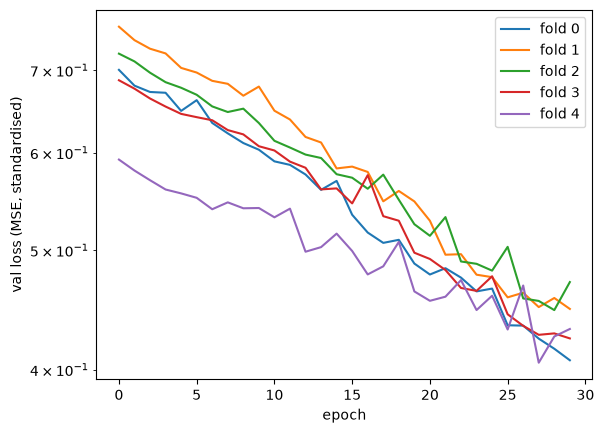

In [53]:
for k, c in enumerate(curves):
    plt.plot(c, label=f"fold {k}")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("val loss (MSE, standardised)"); plt.legend(); plt.show()

## Submission

In [54]:
submission = pd.DataFrame(physical(mlp(test_inputs)), columns=TARGETS)
submission.insert(0, "z_mm", test_inputs.z_mm.to_numpy())
submission.insert(0, "config", test_inputs.config.to_numpy())
submission.to_csv("submission_trajectory.csv", index=False)
print(f"wrote submission_trajectory.csv ({len(submission):,} rows)")

AttributeError: 'DataFrame' object has no attribute 'z_mm'

In [ ]:
EMULATOR = {"E_MeV": 0.9633, "q_pC": 0.9331, "dE_pct": 0.8092, "emit_um": 0.8610, "div_mrad": 0.9469, "sigz_um": 0.8623, "mean": 0.8960}
pd.DataFrame({"linear": score(lin.predict(features(test)), test), "rf": score(rf.predict(features(test)), test),
              "mlp": score(mlp(test), test), "mlp drift": score(mlp(test), test, zone="drift"),
              "internal emulator (medium bar)": EMULATOR}).T[TARGETS + ["mean"]].round(3)

,E_MeV,q_pC,dE_pct,emit_um,div_mrad,sigz_um,mean
linear,-0.353,0.808,0.374,-0.047,0.717,0.598,0.349
rf,0.928,0.829,0.641,0.699,0.863,0.793,0.792
mlp,0.995,0.997,0.980,0.977,0.983,0.966,0.983
mlp drift,0.997,0.999,0.981,NaN,NaN,0.968,0.986
internal emulator (medium bar),0.963,0.933,0.809,0.861,0.947,0.862,0.896
